# PII 마스킹 이식

**이 노트북에서 할 일**

1. Ch16 02절의 가리기 함수를 딕셔너리와 `re.compile`로 정리한 판을 실행해 봅니다.
2. 마스킹 없이 이메일이 든 질문을 보내고, 모델이 받은 글을 확인합니다(Before).
3. 이메일 마스킹 미들웨어를 등록하고 같은 질문을 보냅니다(After).

**준비물** — `.env` 파일의 `OPENAI_API_KEY`. 데이터 파일은 없습니다. 모델 호출은 4번이고 실행 시간은 1분 이내입니다. 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

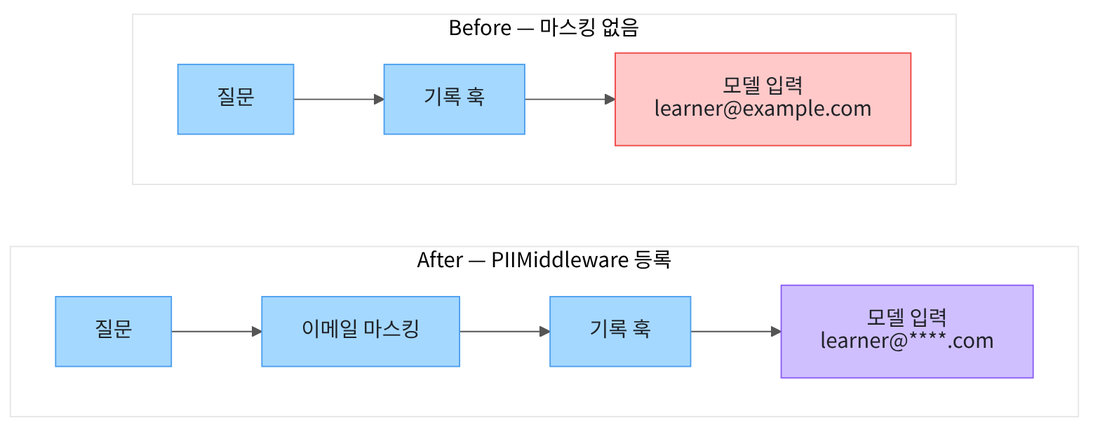

위가 Before, 아래가 After입니다. After에서는 모델에 보내기 전에 마스킹 훅이 이메일을 가립니다.
파란 상자는 질문과 거쳐 가는 단계, 빨간 상자는 원문이 간 모델 입력, 보라 상자는 가려진 모델 입력입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 절에서 쓰는 이름을 불러옵니다. 개인정보를 가리는 미들웨어는 `PIIMiddleware`입니다.

In [2]:
# 에이전트·미들웨어·모델을 만드는 도구를 불러옵니다
import re
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import ModelRequest, ModelResponse, PIIMiddleware
from langchain.agents.middleware import wrap_model_call
from langchain.chat_models import init_chat_model

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다. 01절과 같은 설정입니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

## 2. Ch16 마스킹 함수를 정리한 판

개인정보(PII)는 이메일이나 전화번호처럼 사람을 알아볼 수 있는 정보입니다.
Ch16 02절에서는 정규식으로 개인정보를 찾아 표식으로 바꿨습니다. 정규식은 글자의 모양을 적는 규칙입니다.
이 절은 그 가리기 함수를 딕셔너리와 `re.compile`로 정리한 판을 씁니다.

함수 `re.compile(정규식)`은 정규식 글을 미리 규칙 객체 하나로 만들어 둡니다. 그 객체의 `sub`가 맞는 부분을 바꿉니다.
전화번호·주민등록번호·카드 번호 정규식은 Ch16 02절과 같고, 이메일 정규식은 Ch16 02절과 다른 모양입니다.
먼저 찾을 모양 네 가지를 딕셔너리에 담습니다.

In [5]:
# 찾을 개인정보 모양을 이름별 정규식으로 적습니다
PII_PATTERNS = {
    "email": re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+"),
    "phone": re.compile(r"01[016789]-?\d{3,4}-?\d{4}"),
    "rrn": re.compile(r"\d{6}-?[1-4]\d{6}"),
    "card": re.compile(r"\d{4}-\d{4}-\d{4}-\d{4}"),
}
print("찾을 개인정보 종류:", list(PII_PATTERNS))

찾을 개인정보 종류: ['email', 'phone', 'rrn', 'card']


**결과 읽기** — 네 가지 이름 `email`, `phone`, `rrn`, `card`가 나옵니다. 이름 중 rrn은 주민등록번호, card는 카드 번호입니다.

글 하나를 받아 네 가지 모양을 차례로 표식으로 바꾸는 함수를 만듭니다.
Ch16 02절 함수와 달리 종류별 개수는 내놓지 않고 가린 글만 내놓습니다.

In [6]:
# 정규식에 맞는 부분을 <EMAIL_MASKED> 같은 표식으로 바꾸는 함수
def mask_pii(text: str) -> str:
    masked = text
    for name, pattern in PII_PATTERNS.items():
        label = "<" + name.upper() + "_MASKED>"
        masked = pattern.sub(label, masked)
    return masked

출력은 없습니다. 함수를 만들기만 했습니다. 예시 글로 실행해 봅니다.

In [7]:
# 개인정보 네 가지가 든 예시 글에 함수를 적용합니다
sample = "learner@example.com 010-1234-5678 900101-1234567 1234-5678-9012-3456"
print("원문:", sample)
print("마스킹 결과:", mask_pii(sample))

원문: learner@example.com 010-1234-5678 900101-1234567 1234-5678-9012-3456
마스킹 결과: <EMAIL_MASKED> <PHONE_MASKED> <RRN_MASKED> <CARD_MASKED>


**결과 읽기** — 네 값이 모두 `<EMAIL_MASKED>` 같은 표식으로 바뀌었습니다.
Ch16에서는 모델을 부르기 전에 가리기 함수를 우리가 직접 호출해야 했습니다. 호출을 빠뜨리면 원문이 그대로 모델에 갑니다.

## 3. 모델이 받은 글을 기록하는 훅

이번 비교의 기준은 「모델이 실제로 무엇을 받았나」입니다. 01절의 감싸기형 훅으로 모델 입력을 기록합니다.
`request.messages`에는 이번 모델 호출에 들어가는 메시지 목록이 있습니다.

In [8]:
# 모델이 실제로 받은 메시지를 기록하는 훅을 만듭니다
seen_by_model = []


@wrap_model_call
def record_model_input(request: ModelRequest, handler: Callable) -> ModelResponse:
    for message in request.messages:
        seen_by_model.append(message.text)
    return handler(request)

출력은 없습니다. 이 훅은 모델을 부르기 직전에 메시지 글을 `seen_by_model` 목록에 적습니다.

## 4. Before — 마스킹 없이 보내기

이메일이 든 질문을 보냅니다. 에이전트에는 기록 훅만 등록합니다.

In [9]:
# Before: 마스킹 없이 이메일이 든 질문을 보냅니다
question = {"messages": [{"role": "user", "content": "제 이메일 learner@example.com 으로 대출 연장 안내를 보내 주세요."}]}
plain_agent = create_agent(model, tools=[], middleware=[record_model_input])
plain_result = plain_agent.invoke(question)
print("모델이 받은 글:", seen_by_model[0])

모델이 받은 글: 제 이메일 learner@example.com 으로 대출 연장 안내를 보내 주세요.


**결과 읽기** — 모델이 받은 글에 이메일 `learner@example.com`이 그대로 들어 있습니다.

In [10]:
# 모델 입력에 이메일 원문이 있었는지 참/거짓으로 확인합니다
email_sent = "learner@example.com" in seen_by_model[0]
print("모델 입력에 이메일 원문이 있나:", email_sent)
assert email_sent

모델 입력에 이메일 원문이 있나: True


**결과 읽기** — `True`입니다. 개인정보가 외부 모델 서비스로 그대로 전송됐습니다.

## 5. After — 마스킹 미들웨어 등록하기

`PIIMiddleware()` 클래스로 미들웨어를 만듭니다. 첫 인자 `"email"`은 가릴 종류입니다.
인자 `strategy="mask"`는 값의 일부를 별표로 가리는 방식입니다. 인자 `apply_to_input=True`는 모델에 보내는 입력에 적용하라는 뜻입니다.

인자 `apply_to_output=True`는 모델이 만든 답에도 적용하라는 뜻입니다. 답 쪽 마스킹은 이번에 확인하지 않습니다.

In [11]:
# After: 이메일 마스킹 미들웨어를 만듭니다
email_mask = PIIMiddleware("email", strategy="mask", apply_to_input=True, apply_to_output=True)
print("미들웨어 이름:", email_mask.name)

미들웨어 이름: PIIMiddleware[email]


**결과 읽기** — 미들웨어 이름에 `email`이 들어 있습니다.

기록을 비우고 같은 질문을 보냅니다. 마스킹 미들웨어의 입력 처리는 01절에서 본 before_model 자리에서 실행됩니다.
그래서 모델 호출을 감싸는 기록 훅보다 먼저 글을 바꿉니다.

In [12]:
# 같은 질문을 마스킹 미들웨어가 있는 에이전트로 보냅니다
seen_by_model.clear()
masked_agent = create_agent(model, tools=[], middleware=[email_mask, record_model_input])
masked_result = masked_agent.invoke(question)
print("모델이 받은 글:", seen_by_model[0])

모델이 받은 글: 제 이메일 learner@****.com 으로 대출 연장 안내를 보내 주세요.


**결과 읽기** — 이메일 자리가 `learner@****.com`처럼 별표로 바뀌었습니다. 모델은 가려진 글만 받았습니다.

In [13]:
# 모델 입력과 저장된 대화 기록에 이메일 원문이 남았는지 확인합니다
email_sent = "learner@example.com" in seen_by_model[0]
stored_text = masked_result["messages"][0].text
print("모델 입력에 이메일 원문이 있나:", email_sent)
print("대화 기록에 저장된 질문:", stored_text)
assert not email_sent

모델 입력에 이메일 원문이 있나: False
대화 기록에 저장된 질문: 제 이메일 learner@****.com 으로 대출 연장 안내를 보내 주세요.


**결과 읽기** — 모델 입력 확인 결과가 `False`입니다. 대화 기록에 저장된 질문도 가려진 글로 바뀌었습니다.
이번에는 Ch16 방식과 달리 마스킹 함수를 직접 부르지 않았습니다. 그런데도 모델 호출 전에 적용됐습니다.

## 6. 값 하나 바꿔 보기 — 전화번호

공식 문서 기준으로 내장 종류는 email, credit_card, ip, mac_address, url입니다. 전화번호는 내장 종류에 없습니다.
이메일 마스킹만 등록한 상태에서 전화번호를 보내 봅니다.
실행 전에 예상해 봅니다. 전화번호는 등록하지 않은 종류이므로 그대로 모델에 갈 것입니다.

In [14]:
# 전화번호가 든 질문을 이메일 마스킹 에이전트로 보냅니다
seen_by_model.clear()
phone_question = {"messages": [{"role": "user", "content": "연락처 010-1234-5678 로 문자 안내를 받을 수 있나요?"}]}
masked_agent.invoke(phone_question)
print("모델이 받은 글:", seen_by_model[0])

모델이 받은 글: 연락처 010-1234-5678 로 문자 안내를 받을 수 있나요?


**결과 읽기** — 전화번호 `010-1234-5678`이 그대로 보입니다. 등록한 종류만 가려집니다.

Ch16에서 쓴 전화번호 정규식을 `detector` 인자로 넘기면 전화번호용 미들웨어를 하나 더 만들 수 있습니다.
정규식 객체의 `.pattern` 속성에는 규칙이 글자로 들어 있습니다. 이 글자를 `detector` 인자에 넘깁니다.

In [15]:
# Ch16의 전화번호 정규식으로 마스킹 미들웨어를 하나 더 만듭니다
phone_rule = PII_PATTERNS["phone"].pattern
phone_mask = PIIMiddleware(
    "phone",
    detector=phone_rule,
    strategy="mask",
    apply_to_input=True,
)
print("정규식 규칙:", phone_rule)
print("미들웨어 이름:", phone_mask.name)

정규식 규칙: 01[016789]-?\d{3,4}-?\d{4}
미들웨어 이름: PIIMiddleware[phone]


**결과 읽기** — 미들웨어 이름에 `phone`이 들어 있습니다.

이메일과 전화번호 마스킹 미들웨어를 함께 등록하고 같은 질문을 보냅니다.

In [16]:
# 이메일·전화번호 마스킹을 함께 등록한 에이전트로 같은 질문을 보냅니다
seen_by_model.clear()
both_agent = create_agent(model, tools=[], middleware=[email_mask, phone_mask, record_model_input])
both_agent.invoke(phone_question)
print("모델이 받은 글:", seen_by_model[0])
assert "010-1234-5678" not in seen_by_model[0]

모델이 받은 글: 연락처 ****5678 로 문자 안내를 받을 수 있나요?


**결과 읽기** — 이번에는 전화번호가 `****5678`로 가려졌습니다. 마지막 `assert` 줄이 오류 없이 지나갔습니다.

## 정리

- Ch16의 마스킹 함수는 우리가 부를 때만 적용됩니다. 미들웨어는 모델을 부를 때마다 자동으로 적용됩니다.
- 내장 미들웨어는 등록한 종류만 가립니다. 전화번호처럼 없는 종류는 `detector`에 정규식을 넘겨 추가합니다.
- 비교할 때는 답 문장이 아니라 「모델이 받은 글」을 기록해서 확인했습니다.